# 01 – Exploratory Data Analysis: Telco Customer Churn

**Dự án:** Profit-Aware Telecom Churn & Retention Targeting
**Mục tiêu notebook:** khám phá dữ liệu churn và nhận diện các nhóm khách có hồ sơ **rủi ro (risk) / giá trị (value)** khác nhau.

**Phạm vi:** chỉ **EDA**, không làm preprocessing.
- Không sửa file CSV gốc, không lưu dữ liệu đã xử lý.
- Một vài chuyển đổi kiểu dữ liệu được làm **tạm thời trong bộ nhớ** để vẽ biểu đồ (ví dụ đọc `TotalCharges` dạng số, `Churn` → 0/1). Không có điền giá trị thiếu hay mã hoá biến.
- Mọi vấn đề phát hiện được ghi lại ở mục **8.2 – Ghi chú cho preprocessing**.

**Câu hỏi EDA cần trả lời**
1. Churn tổng thể ở mức nào, tập trung ở đâu?
2. Yếu tố nào gắn với churn (hợp đồng, dịch vụ, thanh toán, nhân khẩu học)?
3. Churn thay đổi thế nào theo vòng đời khách (tenure)?
4. Khách giá trị cao có rủi ro cao hơn không?
5. Có những nhóm khách nào với hồ sơ risk/value khác nhau, quy mô và doanh thu bị đe doạ ra sao?

**Mục lục**
1. Tổng quan dữ liệu
2. Kiểm tra chất lượng dữ liệu
3. Biến mục tiêu
4. Phân tích đơn biến
5. Phân tích hai biến – yếu tố gắn với churn
6. Tương quan & đa biến
7. Góc nhìn rủi ro × giá trị
8. Tổng hợp insight & ghi chú cho preprocessing

## 0. Setup

In [1]:
from math import ceil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
FIG_DIR = ROOT / "eda_output" / "figures"
TAB_DIR = ROOT / "eda_output" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Bảng màu: categorical theo thứ tự cố định, sequential một hue (xanh dương)
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CHURN_COLORS = {"No": BLUE, "Yes": ORANGE}
CONTRACT_COLORS = {"Month-to-month": BLUE, "One year": ORANGE, "Two year": AQUA}
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 100,
})


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def pct(x, digits=1):
    return f"{x:.{digits}%}"


def churn_rate_table(data, col):
    """Số khách, tỉ lệ churn và lift so với churn trung bình cho từng nhóm của `col`."""
    t = data.groupby(col, observed=True)["churn_flag"].agg(n="size", churn_rate="mean")
    t["share"] = t["n"] / len(data)
    t["lift"] = t["churn_rate"] / BASE_RATE
    return t.sort_values("churn_rate", ascending=False)


def plot_churn_rate(data, cols, title, name, ncols=3):
    """Lưới bar chart ngang: tỉ lệ churn theo nhóm, đường đứt = churn trung bình."""
    nrows = ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 0.4 + 2.6 * nrows), squeeze=False)
    for ax, col in zip(axes.flat, cols):
        t = churn_rate_table(data, col).sort_values("churn_rate")
        ax.barh(t.index.astype(str), t["churn_rate"], color=BLUE, height=0.55)
        ax.axvline(BASE_RATE, color=INK_2, ls="--", lw=1)
        for i, (rate, n) in enumerate(zip(t["churn_rate"], t["n"])):
            ax.text(rate + 0.01, i, f"{rate:.0%}  (n={n:,})", va="center", fontsize=8.5, color=INK_2)
        ax.set_xlim(0, max(0.7, t["churn_rate"].max() + 0.25))
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(axis="y", visible=False)
        ax.set_title(col, loc="left")
    for ax in list(axes.flat)[len(cols):]:
        ax.axis("off")
    fig.suptitle(f"{title}  (đường đứt = churn trung bình {BASE_RATE:.1%})",
                 x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout()
    save_fig(fig, name)
    plt.show()

## 1. Tổng quan dữ liệu

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Số dòng: {df.shape[0]:,} | Số cột: {df.shape[1]}")
df.head()

Số dòng: 7,043 | Số cột: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 1.1 Nhóm biến
21 cột được chia thành 7 nhóm theo ý nghĩa nghiệp vụ.

In [5]:
COL_GROUPS = {
    "Định danh": ["customerID"],
    "Nhân khẩu học": ["gender", "SeniorCitizen", "Partner", "Dependents"],
    "Dịch vụ điện thoại": ["PhoneService", "MultipleLines"],
    "Dịch vụ internet": ["InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                         "TechSupport", "StreamingTV", "StreamingMovies"],
    "Hợp đồng & thanh toán": ["Contract", "PaperlessBilling", "PaymentMethod"],
    "Biến số": ["tenure", "MonthlyCharges", "TotalCharges"],
    "Nhãn": ["Churn"],
}
assert sum(len(v) for v in COL_GROUPS.values()) == df.shape[1]

NUM_COLS = COL_GROUPS["Biến số"]
CAT_COLS = [c for g, cols in COL_GROUPS.items() if g not in ("Định danh", "Biến số", "Nhãn") for c in cols]
INTERNET_ADDONS = COL_GROUPS["Dịch vụ internet"][1:]

pd.DataFrame(
    [(g, c, str(df[c].dtype), df[c].nunique()) for g, cols in COL_GROUPS.items() for c in cols],
    columns=["Nhóm", "Cột", "dtype", "Số giá trị khác nhau"],
)

,Nhóm,Cột,dtype,Số giá trị khác nhau
0,Định danh,customerID,object,7043
1,Nhân khẩu học,gender,object,2
2,Nhân khẩu học,SeniorCitizen,int64,2
3,Nhân khẩu học,Partner,object,2
4,Nhân khẩu học,Dependents,object,2
5,Dịch vụ điện thoại,PhoneService,object,2
6,Dịch vụ điện thoại,MultipleLines,object,3
7,Dịch vụ internet,InternetService,object,3
8,Dịch vụ internet,OnlineSecurity,object,3
9,Dịch vụ internet,OnlineBackup,object,3


### 1.2 Các giá trị của biến phân loại

In [6]:
for c in CAT_COLS + ["Churn"]:
    print(f"{c:<17} {df[c].value_counts().to_dict()}")

gender            {'Male': 3555, 'Female': 3488}
SeniorCitizen     {0: 5901, 1: 1142}
Partner           {'No': 3641, 'Yes': 3402}
Dependents        {'No': 4933, 'Yes': 2110}
PhoneService      {'Yes': 6361, 'No': 682}
MultipleLines     {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService   {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity    {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup      {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection  {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport       {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV       {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies   {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract          {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling  {'Yes': 4171, 'No': 2872}
PaymentMethod     {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (autom

## 2. Kiểm tra chất lượng dữ liệu
Mục này **chỉ phát hiện**, không sửa. Kết quả được tổng hợp ở mục 8.2.

### 2.1 Giá trị thiếu và chuỗi rỗng

In [7]:
blank = df.apply(lambda s: s.astype(str).str.strip().eq("").sum())
quality = pd.DataFrame({"NaN": df.isna().sum(), "Chuỗi rỗng": blank})
print("Tổng NaN:", int(quality["NaN"].sum()))
quality[quality.sum(axis=1) > 0]

Tổng NaN: 0


,NaN,Chuỗi rỗng
TotalCharges,0,11


In [8]:
tc_num = pd.to_numeric(df["TotalCharges"], errors="coerce")   # chỉ dùng tạm để phân tích
blank_tc = tc_num.isna()
print(f"Số dòng TotalCharges không đọc được thành số: {blank_tc.sum()}")
print(f"tenure của các dòng này: {sorted(df.loc[blank_tc, 'tenure'].unique())}")
print(f"Tổng số khách có tenure = 0: {(df['tenure'] == 0).sum()}")
df.loc[blank_tc, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Số dòng TotalCharges không đọc được thành số: 11
tenure của các dòng này: [np.int64(0)]
Tổng số khách có tenure = 0: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


### 2.2 Kiểu dữ liệu chưa phù hợp

In [9]:
print(df[["SeniorCitizen", "TotalCharges"]].dtypes, "\n")
print("SeniorCitizen:", df["SeniorCitizen"].value_counts().to_dict(),
      "→ mã hoá 0/1, khác các cột nhị phân còn lại (Yes/No)")

SeniorCitizen     int64
TotalCharges     object
dtype: object 

SeniorCitizen: {0: 5901, 1: 1142} → mã hoá 0/1, khác các cột nhị phân còn lại (Yes/No)


### 2.3 Trùng lặp

In [10]:
print("customerID trùng:", df["customerID"].duplicated().sum())
dup_rows = df.drop(columns="customerID").duplicated(keep=False)
print("Dòng trùng toàn bộ đặc trưng (bỏ customerID):", df.drop(columns="customerID").duplicated().sum(),
      f"(liên quan {dup_rows.sum()} dòng)")
df.loc[dup_rows, ["tenure", "Contract", "InternetService", "MonthlyCharges", "Churn"]].describe(include="all").loc[["count", "unique", "top"]]

customerID trùng: 0
Dòng trùng toàn bộ đặc trưng (bỏ customerID): 22 (liên quan 42 dòng)


,tenure,Contract,InternetService,MonthlyCharges,Churn
count,42.0,42,42,42.0,42
unique,NaN,1,3,NaN,2
top,NaN,Month-to-month,No,NaN,Yes


### 2.4 Tính nhất quán
**(a)** `TotalCharges` có xấp xỉ `tenure × MonthlyCharges` không? Độ lệch cho biết khách đã thay đổi gói cước trong quá khứ.

In [11]:
expected = df["tenure"] * df["MonthlyCharges"]
gap = ((tc_num - expected) / expected).replace([np.inf, -np.inf], np.nan)
print(f"Tương quan Pearson TotalCharges ~ tenure×MonthlyCharges: {tc_num.corr(expected):.4f}")
print(f"Tỉ lệ khách lệch > 10%: {(gap.abs() > 0.10).mean():.1%}")
gap.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("Độ lệch tương đối")

Tương quan Pearson TotalCharges ~ tenure×MonthlyCharges: 0.9996
Tỉ lệ khách lệch > 10%: 5.4%


,Độ lệch tương đối
count,7032.000000
mean,0.000275
std,0.051159
min,-0.310644
5%,-0.075549
25%,-0.020454
50%,0.000000
75%,0.019562
95%,0.074816
max,0.573454


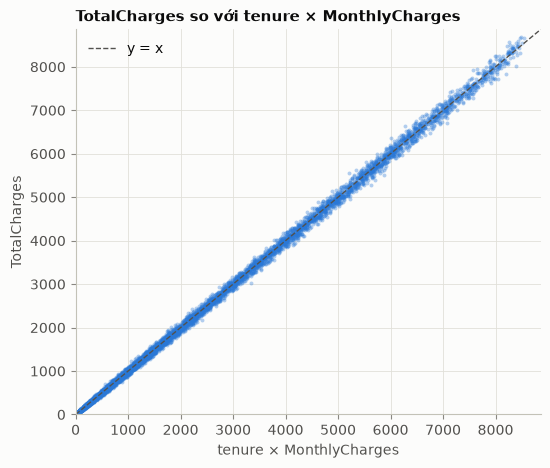

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(expected, tc_num, s=8, alpha=0.35, color=BLUE, linewidths=0)
lim = [0, max(expected.max(), tc_num.max()) * 1.02]
ax.plot(lim, lim, color=INK_2, ls="--", lw=1, label="y = x")
ax.set(xlim=lim, ylim=lim, xlabel="tenure × MonthlyCharges", ylabel="TotalCharges")
ax.set_title("TotalCharges so với tenure × MonthlyCharges", loc="left")
ax.legend(loc="upper left")
save_fig(fig, "q01_totalcharges_consistency")
plt.show()

**(b)** Ràng buộc logic giữa các cột dịch vụ: khách không có dịch vụ gốc (`InternetService = No` / `PhoneService = No`) thì các cột dịch vụ con phải mang nhãn `"No internet service"` / `"No phone service"`, và ngược lại.

In [13]:
rules = [(c, df["InternetService"].eq("No"), "No internet service") for c in INTERNET_ADDONS]
rules.append(("MultipleLines", df["PhoneService"].eq("No"), "No phone service"))

logic = pd.DataFrame(
    [(c, base.sum(), (base & df[c].ne(label)).sum(), (~base & df[c].eq(label)).sum())
     for c, base, label in rules],
    columns=["Cột", "Khách không có dịch vụ gốc", "Vi phạm: không có gốc nhưng nhãn khác",
             "Vi phạm: có gốc nhưng nhãn 'No ... service'"],
)
logic

,Cột,Khách không có dịch vụ gốc,Vi phạm: không có gốc nhưng nhãn khác,Vi phạm: có gốc nhưng nhãn 'No ... service'
0,OnlineSecurity,1526,0,0
1,OnlineBackup,1526,0,0
2,DeviceProtection,1526,0,0
3,TechSupport,1526,0,0
4,StreamingTV,1526,0,0
5,StreamingMovies,1526,0,0
6,MultipleLines,682,0,0


### 2.5 Giá trị ngoại lai (IQR)

,min,Q1,median,Q3,max,Số ngoại lai (1.5×IQR)
tenure,0.00,9.00,29.00,55.00,72.00,0
MonthlyCharges,18.25,35.50,70.35,89.85,118.75,0
TotalCharges,18.80,401.45,1397.48,3794.74,8684.80,0


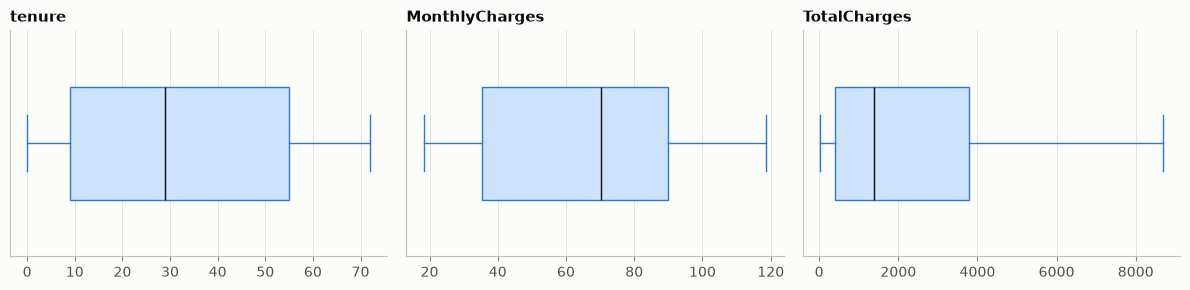

In [14]:
num = df[["tenure", "MonthlyCharges"]].assign(TotalCharges=tc_num)
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
outlier_count = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({"min": num.min(), "Q1": q1, "median": num.median(), "Q3": q3,
                      "max": num.max(), "Số ngoại lai (1.5×IQR)": outlier_count}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, c in zip(axes, NUM_COLS):
    ax.boxplot(num[c].dropna(), orientation="horizontal", widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
               medianprops=dict(color=INK), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor="none"))
    ax.set_yticks([])
    ax.set_title(c, loc="left")
fig.tight_layout()
save_fig(fig, "q02_boxplots")
plt.show()

### 2.6 Bảng phân tích tạm thời
Để vẽ biểu đồ, tạo một bản sao `eda` **chỉ dùng trong notebook này**:
- `TotalCharges` đọc dạng số. 11 giá trị rỗng **giữ nguyên NaN**, không điền.
- `churn_flag` = 1 nếu `Churn = Yes`, dùng để tính tỉ lệ churn.
- `SeniorCitizen` hiển thị dạng Yes/No cho đồng nhất trên biểu đồ.

File gốc không thay đổi.

In [15]:
eda = df.copy()
eda["TotalCharges"] = tc_num
eda["churn_flag"] = eda["Churn"].eq("Yes").astype(int)
eda["SeniorCitizen"] = eda["SeniorCitizen"].map({0: "No", 1: "Yes"})
eda.shape

(7043, 22)

## 3. Biến mục tiêu – Churn

,n,tỉ lệ
Churn,,
No,"5,174",73.5%
Yes,"1,869",26.5%


Tỉ lệ churn trung bình (BASE_RATE): 26.54%  |  tỉ lệ No:Yes ≈ 2.8:1


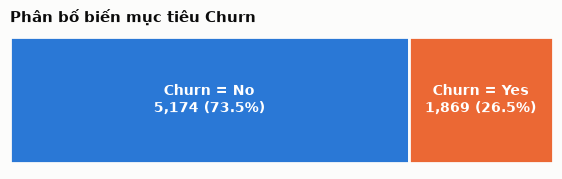

In [16]:
BASE_RATE = eda["churn_flag"].mean()
target = eda["Churn"].value_counts().to_frame("n")
target["tỉ lệ"] = target["n"] / target["n"].sum()
display(target.style.format({"n": "{:,}", "tỉ lệ": "{:.1%}"}))
print(f"Tỉ lệ churn trung bình (BASE_RATE): {BASE_RATE:.2%}  |  tỉ lệ No:Yes ≈ {(1 - BASE_RATE) / BASE_RATE:.1f}:1")

fig, ax = plt.subplots(figsize=(7, 1.8))
left = 0
for label in ["No", "Yes"]:
    n = target.loc[label, "n"]
    ax.barh([0], [n], left=left, color=CHURN_COLORS[label], height=0.5, edgecolor=SURFACE, linewidth=2)
    ax.text(left + n / 2, 0, f"Churn = {label}\n{n:,} ({target.loc[label, 'tỉ lệ']:.1%})",
            ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += n
ax.set_xlim(0, len(eda))
ax.axis("off")
ax.set_title("Phân bố biến mục tiêu Churn", loc="left")
save_fig(fig, "f01_churn_distribution")
plt.show()

**Nhận xét:** dữ liệu **mất cân bằng vừa phải**, cứ khoảng 2.8 khách ở lại thì có 1 khách churn. Hệ quả cho bước mô hình:
- Accuracy dễ gây hiểu lầm. Nên dùng **PR-AUC**, ROC-AUC và Brier score.
- Chia dữ liệu theo **stratified split**.

## 4. Phân tích đơn biến

### 4.1 Biến phân loại – phân bố số khách

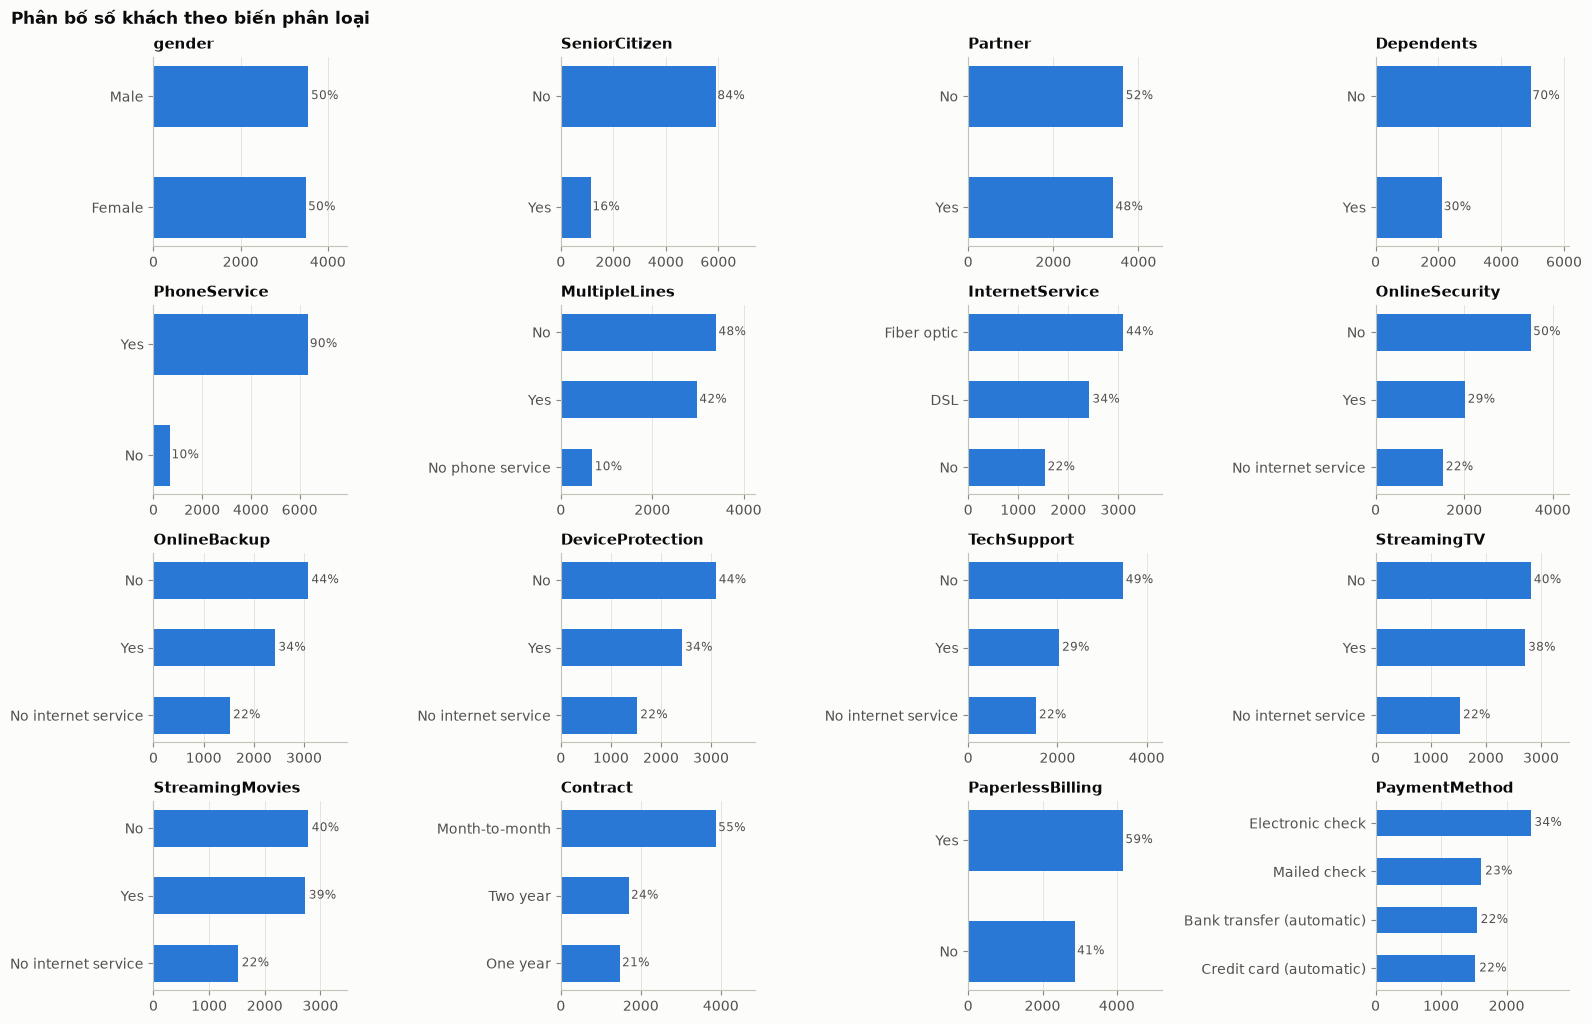

In [17]:
ncols = 4
nrows = ceil(len(CAT_COLS) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.6 * nrows))
for ax, c in zip(axes.flat, CAT_COLS):
    vc = eda[c].value_counts()
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1], color=BLUE, height=0.55)
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v + 60, i, f"{v / len(eda):.0%}", va="center", fontsize=8.5, color=INK_2)
    ax.set_xlim(0, vc.max() * 1.25)
    ax.grid(axis="y", visible=False)
    ax.set_title(c, loc="left")
for ax in list(axes.flat)[len(CAT_COLS):]:
    ax.axis("off")
fig.suptitle("Phân bố số khách theo biến phân loại", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "f02_categorical_distribution")
plt.show()

### 4.2 Biến số – phân phối

,count,mean,std,min,25%,50%,75%,max,skew
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,0.96


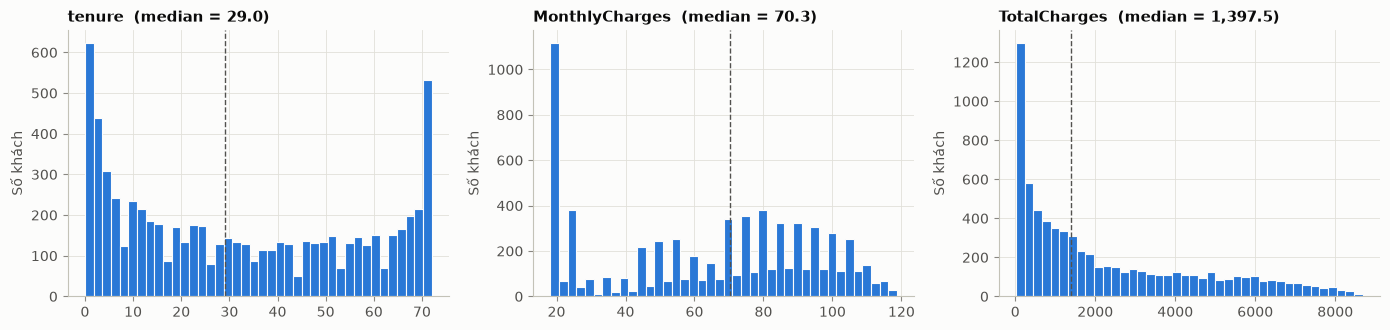

In [18]:
display(eda[NUM_COLS].describe().T.assign(skew=eda[NUM_COLS].skew()).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, c in zip(axes, NUM_COLS):
    ax.hist(eda[c].dropna(), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    ax.axvline(eda[c].median(), color=INK_2, ls="--", lw=1)
    ax.set_title(f"{c}  (median = {eda[c].median():,.1f})", loc="left")
    ax.set_ylabel("Số khách")
fig.tight_layout()
save_fig(fig, "f03_numeric_distribution")
plt.show()

## 5. Phân tích hai biến – yếu tố gắn với churn
### 5.1 Tỉ lệ churn theo biến phân loại
Mỗi thanh là tỉ lệ churn của một nhóm, kèm số khách `n`. Đường đứt là mức churn trung bình. Thanh nằm bên phải đường đứt là nhóm có rủi ro cao hơn trung bình.

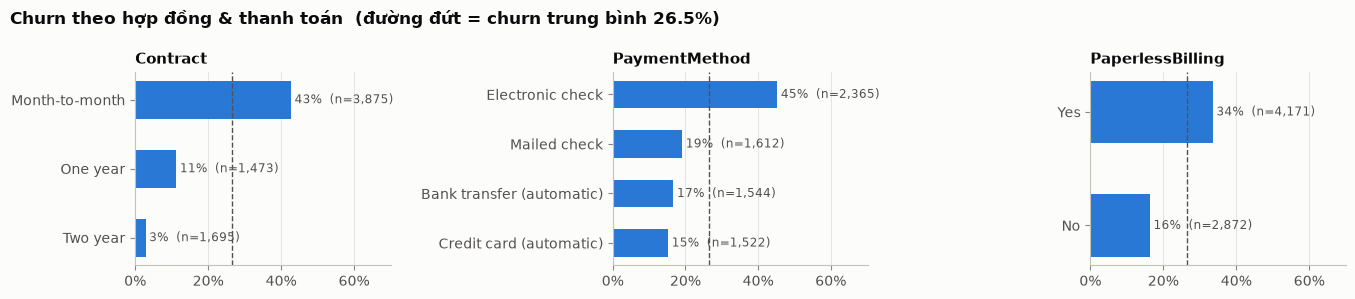

In [19]:
plot_churn_rate(eda, ["Contract", "PaymentMethod", "PaperlessBilling"],
                "Churn theo hợp đồng & thanh toán", "f04_churn_contract_billing")

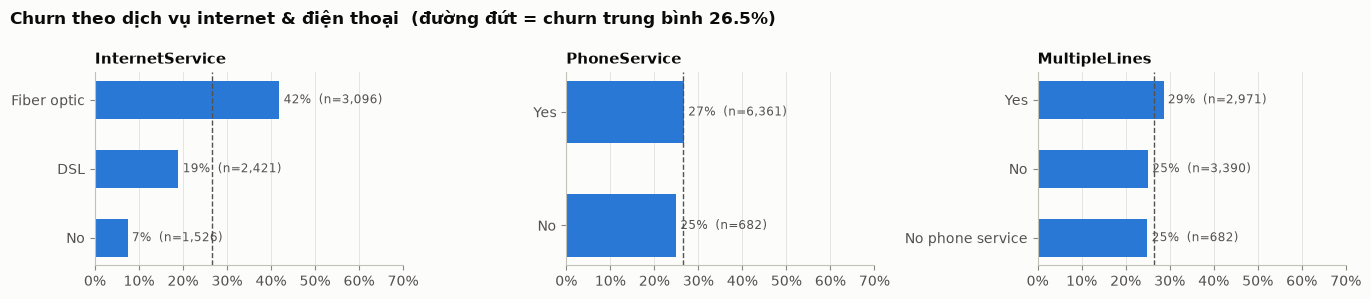

In [20]:
plot_churn_rate(eda, ["InternetService", "PhoneService", "MultipleLines"],
                "Churn theo dịch vụ internet & điện thoại", "f05_churn_internet_phone")

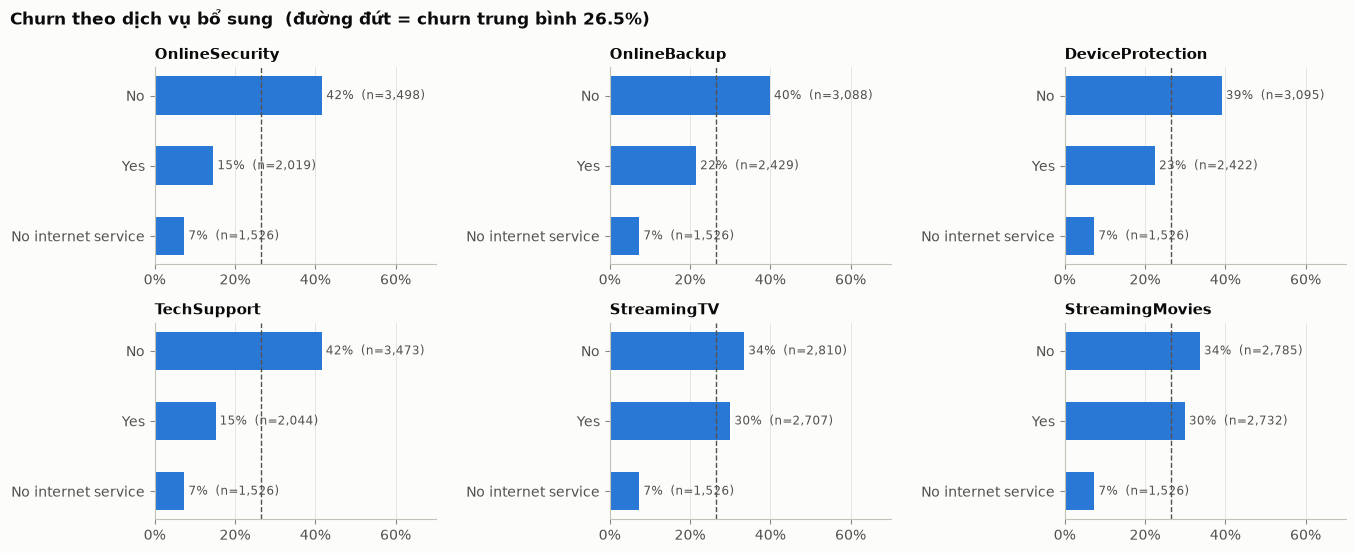

In [21]:
plot_churn_rate(eda, INTERNET_ADDONS, "Churn theo dịch vụ bổ sung", "f06_churn_addons")

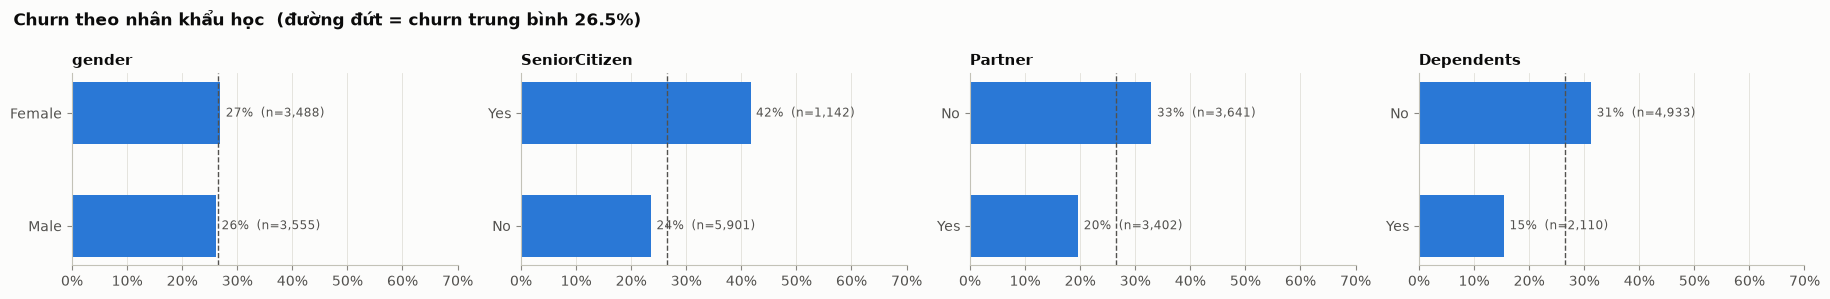

In [22]:
plot_churn_rate(eda, ["gender", "SeniorCitizen", "Partner", "Dependents"],
                "Churn theo nhân khẩu học", "f07_churn_demographics", ncols=4)

### 5.2 Biến số theo Churn

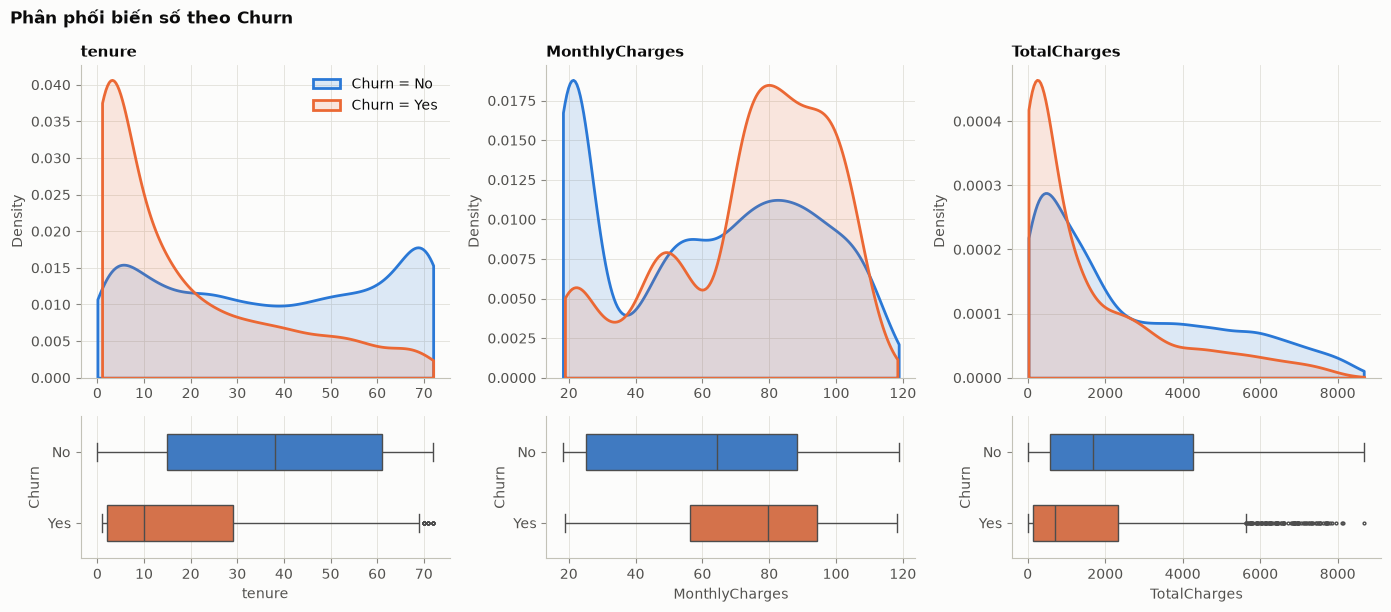

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.2), gridspec_kw={"height_ratios": [2.2, 1]})
for j, c in enumerate(NUM_COLS):
    ax = axes[0, j]
    for label in ["No", "Yes"]:
        sns.kdeplot(eda.loc[eda["Churn"] == label, c].dropna(), ax=ax, color=CHURN_COLORS[label],
                    lw=2, fill=True, alpha=0.15, label=f"Churn = {label}", cut=0)
    ax.set_title(c, loc="left")
    ax.set_xlabel("")
    if j == 0:
        ax.legend(loc="upper right")
    ax_b = axes[1, j]
    sns.boxplot(data=eda, x=c, y="Churn", order=["No", "Yes"], hue="Churn", palette=CHURN_COLORS,
                ax=ax_b, width=0.5, fliersize=2, linewidth=1, legend=False)
    ax_b.set_ylabel("Churn")
fig.suptitle("Phân phối biến số theo Churn", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "f08_numeric_by_churn")
plt.show()

### 5.3 Kiểm định thống kê
- **Biến phân loại:** kiểm định Chi-square độc lập. Độ mạnh liên hệ đo bằng **Cramér's V** (0 = không liên hệ, khoảng 0.1 yếu, khoảng 0.3 trung bình, từ 0.5 trở lên mạnh).
- **Biến số:** kiểm định **Mann-Whitney U** (phi tham số, vì phân phối lệch). Độ lớn hiệu ứng đo bằng **rank-biserial r**, dương nghĩa là nhóm churn có giá trị cao hơn.

In [24]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    return chi2, dof, p, np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


cat_stats = pd.DataFrame(
    [(c, *cramers_v(eda[c], eda["Churn"])) for c in CAT_COLS],
    columns=["Biến", "chi2", "dof", "p_value", "cramers_v"],
).sort_values("cramers_v", ascending=False).reset_index(drop=True)
cat_stats["Có ý nghĩa (α=0.05)"] = cat_stats["p_value"] < 0.05
cat_stats.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}", "cramers_v": "{:.3f}"})

,Biến,chi2,dof,p_value,cramers_v,Có ý nghĩa (α=0.05)
0,Contract,1184.6,2,5.86e-258,0.410,True
1,OnlineSecurity,850.0,2,2.66e-185,0.347,True
2,TechSupport,828.2,2,1.44e-180,0.343,True
3,InternetService,732.3,2,9.57e-160,0.322,True
4,PaymentMethod,648.1,3,3.68e-140,0.303,True
5,OnlineBackup,601.8,2,2.08e-131,0.292,True
6,DeviceProtection,558.4,2,5.51e-122,0.282,True
7,StreamingMovies,375.7,2,2.67e-82,0.231,True
8,StreamingTV,374.2,2,5.53e-82,0.231,True
9,PaperlessBilling,258.3,1,4.07e-58,0.191,True


In [25]:
rows = []
for c in NUM_COLS:
    yes = eda.loc[eda["churn_flag"] == 1, c].dropna()
    no = eda.loc[eda["churn_flag"] == 0, c].dropna()
    u, p = stats.mannwhitneyu(yes, no, alternative="two-sided")
    rows.append((c, no.median(), yes.median(), u, p, 2 * u / (len(yes) * len(no)) - 1))
num_stats = pd.DataFrame(rows, columns=["Biến", "Median (No)", "Median (Yes)", "U", "p_value", "rank_biserial_r"])
num_stats.style.format({"Median (No)": "{:.2f}", "Median (Yes)": "{:.2f}", "U": "{:,.0f}",
                        "p_value": "{:.2e}", "rank_biserial_r": "{:+.3f}"})

,Biến,Median (No),Median (Yes),U,p_value,rank_biserial_r
0,tenure,38.00,10.00,"2,515,538",2.42e-208,-0.480
1,MonthlyCharges,64.43,79.65,"6,003,126",3.31e-54,+0.242
2,TotalCharges,1683.60,703.55,"3,360,665",2.00e-84,-0.303


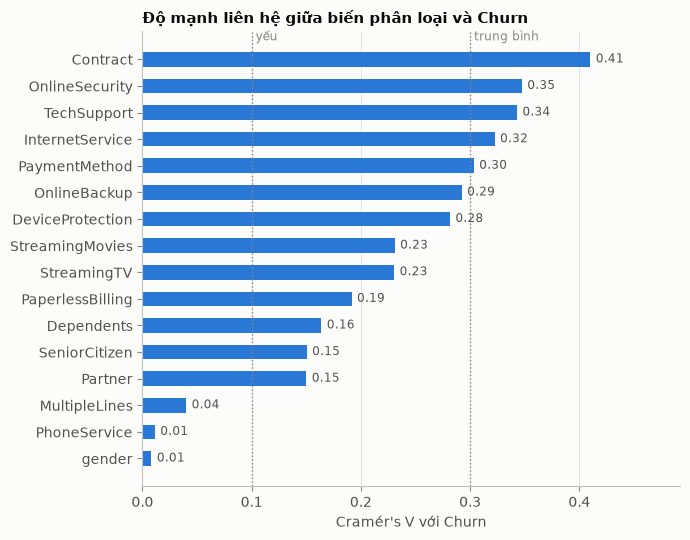

In [26]:
fig, ax = plt.subplots(figsize=(7, 5.5))
s = cat_stats.sort_values("cramers_v")
ax.barh(s["Biến"], s["cramers_v"], color=BLUE, height=0.55)
for i, v in enumerate(s["cramers_v"]):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK_2)
for x, lab in [(0.1, "yếu"), (0.3, "trung bình")]:
    ax.axvline(x, color=MUTED, ls=":", lw=1)
    ax.text(x, len(s) - 0.4, f" {lab}", color=MUTED, fontsize=8.5, va="bottom")
ax.set_xlim(0, s["cramers_v"].max() * 1.2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Cramér's V với Churn")
ax.set_title("Độ mạnh liên hệ giữa biến phân loại và Churn", loc="left")
fig.tight_layout()
save_fig(fig, "f09_association_strength")
plt.show()

### 5.4 Bảng xếp hạng driver (churn rate & lift)
**Lift** = churn rate của nhóm / churn trung bình. Lift = 2 nghĩa là nhóm đó churn gấp đôi mức trung bình. Bảng đầy đủ được lưu ở `eda_output/eda/driver_ranking.csv`.

Các nhóm `"No internet service"` (6 cột dịch vụ bổ sung) và `"No phone service"` (`MultipleLines`) **trùng hoàn toàn** với `InternetService = No` / `PhoneService = No` (đã kiểm tra ở mục 2.4b). Vì vậy chúng bị loại khỏi bảng xếp hạng để tránh lặp.

In [27]:
driver = pd.concat(
    [churn_rate_table(eda, c).rename_axis("Nhóm").reset_index().assign(Biến=c) for c in CAT_COLS],
    ignore_index=True,
)[["Biến", "Nhóm", "n", "share", "churn_rate", "lift"]]
driver = driver[~driver["Nhóm"].isin(["No internet service", "No phone service"])]
driver = driver.sort_values("lift", ascending=False).reset_index(drop=True)
driver.to_csv(TAB_DIR / "driver_ranking.csv", index=False)

fmt = {"n": "{:,}", "share": "{:.1%}", "churn_rate": "{:.1%}", "lift": "{:.2f}×"}
print("Top 12 nhóm rủi ro cao nhất")
display(driver.head(12).style.format(fmt))
print("Top 8 nhóm rủi ro thấp nhất")
display(driver.tail(8).iloc[::-1].style.format(fmt))

Top 12 nhóm rủi ro cao nhất


,Biến,Nhóm,n,share,churn_rate,lift
0,PaymentMethod,Electronic check,"2,365",33.6%,45.3%,1.71×
1,Contract,Month-to-month,"3,875",55.0%,42.7%,1.61×
2,InternetService,Fiber optic,"3,096",44.0%,41.9%,1.58×
3,OnlineSecurity,No,"3,498",49.7%,41.8%,1.57×
4,SeniorCitizen,Yes,"1,142",16.2%,41.7%,1.57×
5,TechSupport,No,"3,473",49.3%,41.6%,1.57×
6,OnlineBackup,No,"3,088",43.8%,39.9%,1.50×
7,DeviceProtection,No,"3,095",43.9%,39.1%,1.47×
8,StreamingMovies,No,"2,785",39.5%,33.7%,1.27×
9,PaperlessBilling,Yes,"4,171",59.2%,33.6%,1.26×


Top 8 nhóm rủi ro thấp nhất


,Biến,Nhóm,n,share,churn_rate,lift
35,Contract,Two year,"1,695",24.1%,2.8%,0.11×
34,InternetService,No,"1,526",21.7%,7.4%,0.28×
33,Contract,One year,"1,473",20.9%,11.3%,0.42×
32,OnlineSecurity,Yes,"2,019",28.7%,14.6%,0.55×
31,TechSupport,Yes,"2,044",29.0%,15.2%,0.57×
30,PaymentMethod,Credit card (automatic),"1,522",21.6%,15.2%,0.57×
29,Dependents,Yes,"2,110",30.0%,15.5%,0.58×
28,PaperlessBilling,No,"2,872",40.8%,16.3%,0.62×


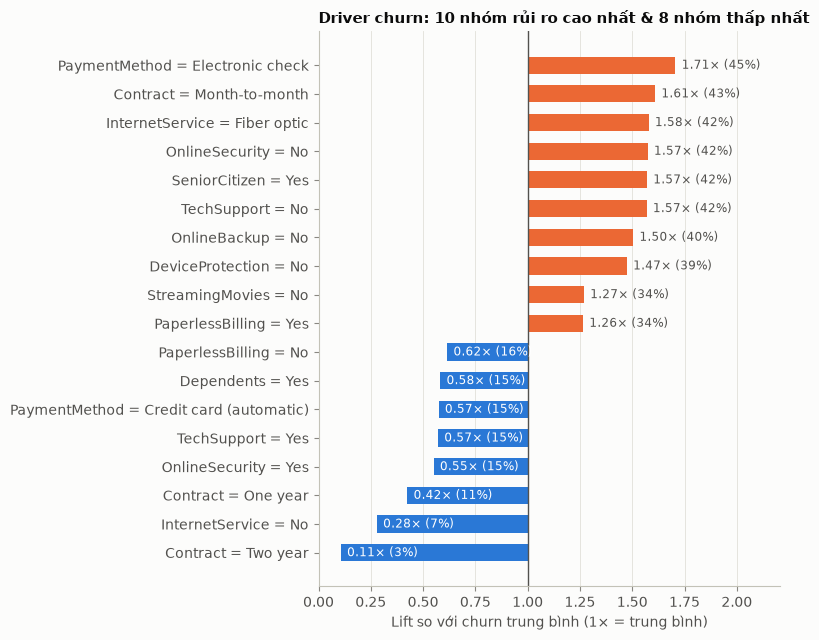

In [28]:
top_bottom = pd.concat([driver.head(10), driver.tail(8)]).iloc[::-1]
labels = top_bottom["Biến"] + " = " + top_bottom["Nhóm"].astype(str)
colors = np.where(top_bottom["lift"] >= 1, ORANGE, BLUE)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(labels, top_bottom["lift"] - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color=INK_2, lw=1)
for i, (lift, rate) in enumerate(zip(top_bottom["lift"], top_bottom["churn_rate"])):
    # nhãn của thanh < 1× nằm trong thanh để không đè lên nhãn trục
    color = INK_2 if lift >= 1 else "white"
    ax.text(lift + 0.03, i, f"{lift:.2f}× ({rate:.0%})", va="center", fontsize=8.5, color=color)
ax.set_xlim(0, top_bottom["lift"].max() + 0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Lift so với churn trung bình (1× = trung bình)")
ax.set_title("Driver churn: 10 nhóm rủi ro cao nhất & 8 nhóm thấp nhất", loc="left")
fig.tight_layout()
save_fig(fig, "f10_driver_lift")
plt.show()

## 6. Tương quan & đa biến

### 6.1 Tương quan giữa các biến số

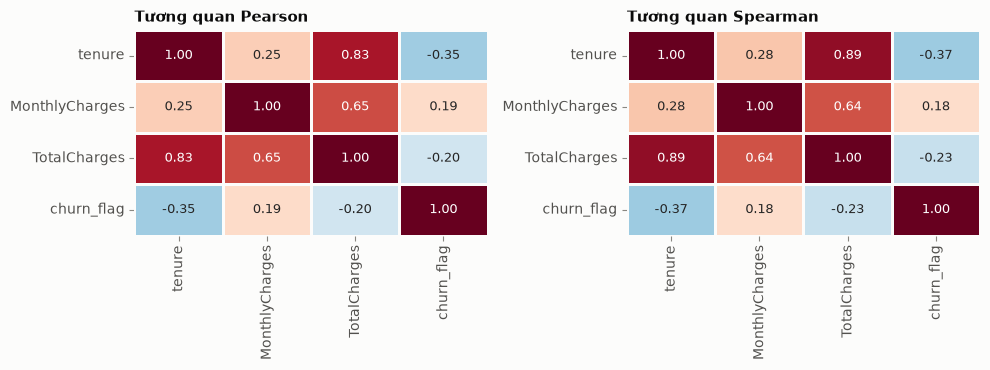

,VIF
tenure,5.84
MonthlyCharges,3.23
TotalCharges,9.53


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = eda[NUM_COLS + ["churn_flag"]].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                linewidths=2, linecolor=SURFACE, cbar=False, ax=ax, annot_kws={"fontsize": 9})
    ax.set_title(f"Tương quan {method.capitalize()}", loc="left")
fig.tight_layout()
save_fig(fig, "f11_correlation")
plt.show()

X_vif = eda[NUM_COLS].dropna().assign(const=1.0)
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(len(NUM_COLS))],
                index=NUM_COLS, name="VIF")
vif.round(2).to_frame()

### 6.2 Tương tác giữa hợp đồng, internet và phương thức thanh toán
Mỗi ô ghi tỉ lệ churn và số khách. Màu càng đậm thì churn càng cao.

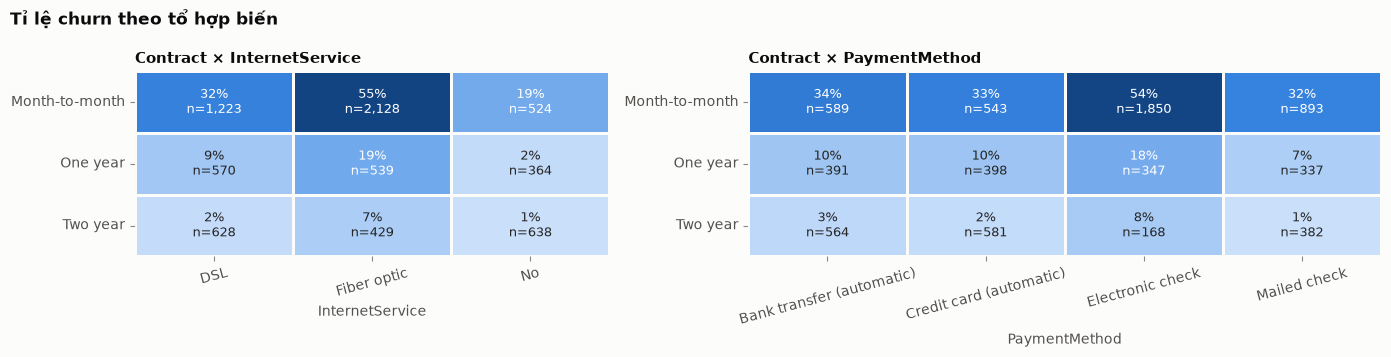

In [30]:
def churn_heatmap(ax, row, col):
    rate = eda.pivot_table(index=row, columns=col, values="churn_flag", aggfunc="mean", observed=True)
    n = eda.pivot_table(index=row, columns=col, values="churn_flag", aggfunc="size", observed=True)
    annot = rate.map(lambda v: f"{v:.0%}" if pd.notna(v) else "") + n.map(lambda v: f"\nn={v:,.0f}" if pd.notna(v) else "")
    sns.heatmap(rate, annot=annot, fmt="", cmap=SEQ_CMAP, vmin=0, vmax=0.6, linewidths=2,
                linecolor=SURFACE, cbar=False, ax=ax, annot_kws={"fontsize": 9})
    ax.set_title(f"{row} × {col}", loc="left")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.tick_params(axis="y", rotation=0)


fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [3, 4]})
churn_heatmap(axes[0], "Contract", "InternetService")
churn_heatmap(axes[1], "Contract", "PaymentMethod")
fig.suptitle("Tỉ lệ churn theo tổ hợp biến", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "f12_heatmap_interactions")
plt.show()

### 6.3 Churn theo vòng đời khách (tenure)
`tenure` được chia khoảng **chỉ để vẽ biểu đồ**, không phải feature cho mô hình.

Contract,Month-to-month,One year,Two year,Tổng
tenure,,,,
0–6,55.2% (n=1413),10.3% (n=39),0.0% (n=29),52.9%
7–12,42.0% (n=581),10.6% (n=85),0.0% (n=39),35.9%
13–24,37.7% (n=737),8.1% (n=197),0.0% (n=90),28.7%
25–48,32.9% (n=802),10.6% (n=518),2.2% (n=274),20.4%
49–72,26.0% (n=342),12.9% (n=634),3.3% (n=1263),9.5%


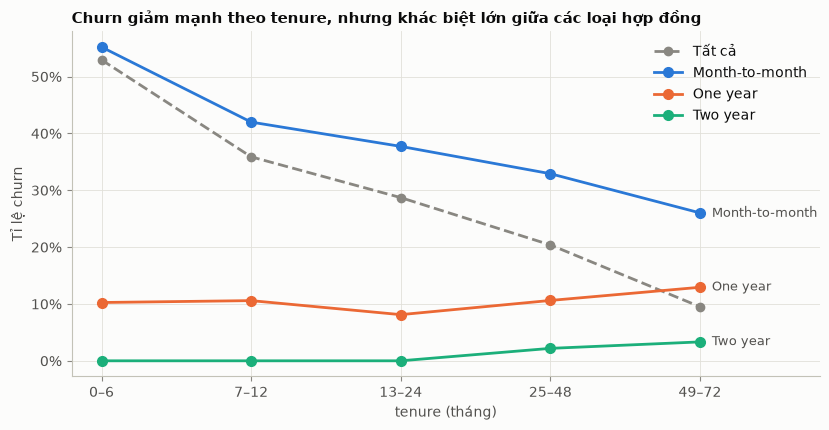

In [31]:
TENURE_BINS = [-1, 6, 12, 24, 48, 72]
TENURE_LABELS = ["0–6", "7–12", "13–24", "25–48", "49–72"]
tenure_group = pd.cut(eda["tenure"], TENURE_BINS, labels=TENURE_LABELS)

by_tenure = eda.groupby([tenure_group, "Contract"], observed=True)["churn_flag"].agg(["mean", "size"]).unstack()
overall = eda.groupby(tenure_group, observed=True)["churn_flag"].mean()
display((by_tenure["mean"].map(pct) + " (n=" + by_tenure["size"].astype("Int64").astype(str) + ")")
        .assign(**{"Tổng": overall.map(pct)}))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(len(TENURE_LABELS))
ax.plot(x, overall.values, color=MUTED, lw=2, ls="--", marker="o", ms=6, label="Tất cả")
for contract, color in CONTRACT_COLORS.items():
    y = by_tenure["mean"][contract].values
    ax.plot(x, y, color=color, lw=2, marker="o", ms=7, label=contract)
    ax.text(x[-1] + 0.08, y[-1], contract, color=INK_2, va="center", fontsize=9)
ax.set_xticks(x, TENURE_LABELS)
ax.set_xlim(-0.2, len(x) - 0.2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="tenure (tháng)", ylabel="Tỉ lệ churn")
ax.set_title("Churn giảm mạnh theo tenure, nhưng khác biệt lớn giữa các loại hợp đồng", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "f13_churn_by_tenure_contract")
plt.show()

### 6.4 tenure × MonthlyCharges

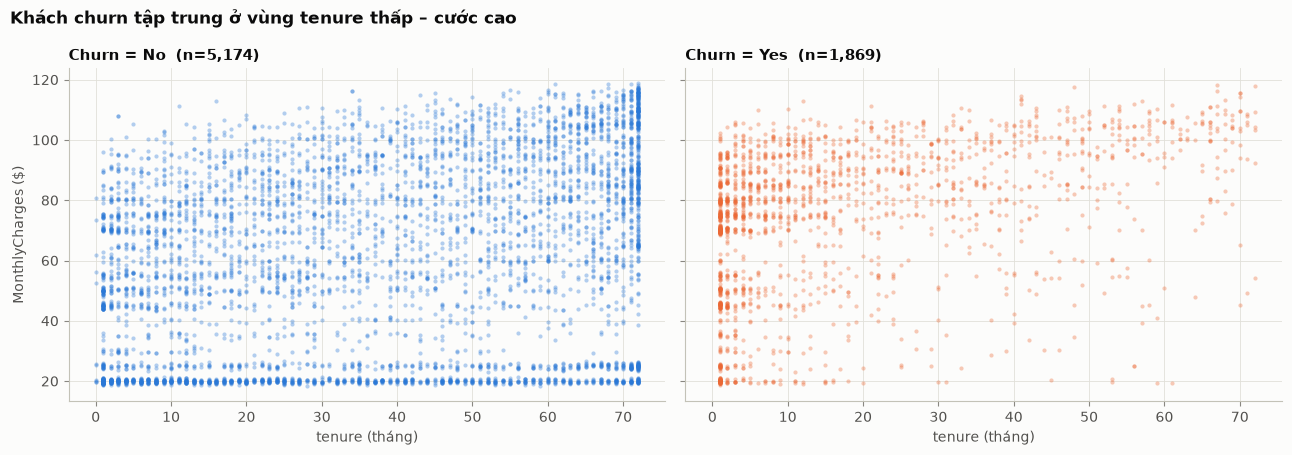

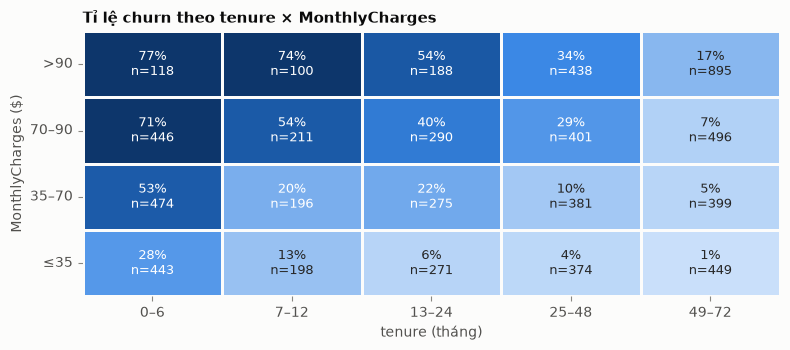

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True, sharey=True)
for ax, label in zip(axes, ["No", "Yes"]):
    sub = eda[eda["Churn"] == label]
    ax.scatter(sub["tenure"], sub["MonthlyCharges"], s=9, alpha=0.35, color=CHURN_COLORS[label], linewidths=0)
    ax.set_title(f"Churn = {label}  (n={len(sub):,})", loc="left")
    ax.set_xlabel("tenure (tháng)")
axes[0].set_ylabel("MonthlyCharges ($)")
fig.suptitle("Khách churn tập trung ở vùng tenure thấp – cước cao", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "f14_scatter_tenure_charges")
plt.show()

# Tỉ lệ churn theo lưới tenure × MonthlyCharges
charge_band = pd.cut(eda["MonthlyCharges"], [0, 35, 70, 90, 120], labels=["≤35", "35–70", "70–90", ">90"])
grid = eda.pivot_table(index=charge_band, columns=tenure_group, values="churn_flag", aggfunc="mean", observed=True)
grid_n = eda.pivot_table(index=charge_band, columns=tenure_group, values="churn_flag", aggfunc="size", observed=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(grid.iloc[::-1], annot=(grid.map(pct, digits=0) + "\nn=" + grid_n.astype(str)).iloc[::-1], fmt="",
            cmap=SEQ_CMAP, vmin=0, vmax=0.7, linewidths=2, linecolor=SURFACE, cbar=False, ax=ax, annot_kws={"fontsize": 9})
ax.set(xlabel="tenure (tháng)", ylabel="MonthlyCharges ($)")
ax.tick_params(axis="y", rotation=0)
ax.set_title("Tỉ lệ churn theo tenure × MonthlyCharges", loc="left")
fig.tight_layout()
save_fig(fig, "f15_heatmap_tenure_charges")
plt.show()

## 7. Góc nhìn rủi ro × giá trị
Ở giai đoạn EDA chưa có mô hình, nên:
- **Risk** = tỉ lệ churn thực tế của nhóm khách.
- **Value** = `MonthlyCharges` (doanh thu hàng tháng), dùng làm proxy tạm thời. Ở bước sau sẽ thay bằng `value_proxy = MonthlyCharges × margin × số tháng còn lại`, với tham số lấy từ `config.yaml`.

### 7.1 Khách giá trị cao có churn nhiều hơn không?

Ngưỡng chia value tier (tercile MonthlyCharges): [ 18.25  50.4   83.9  118.75]


,n,churn_rate,share,lift,avg_monthly
value_tier,,,,,
Low,"2,351",15.9%,33.4%,0.60×,$28.0
Med,"2,345",29.7%,33.3%,1.12×,$69.0
High,"2,347",34.1%,33.3%,1.28×,$97.3


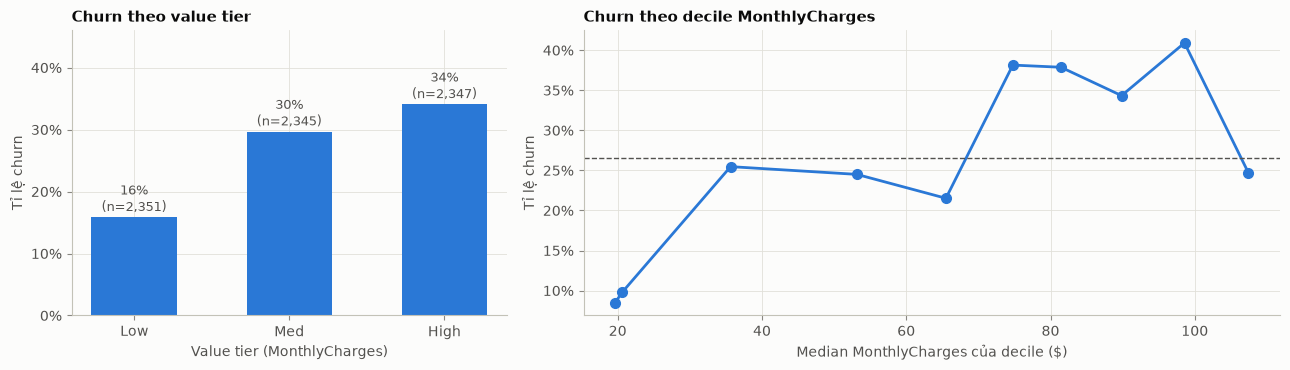

In [33]:
value_tier, VALUE_EDGES = pd.qcut(eda["MonthlyCharges"], 3, labels=["Low", "Med", "High"], retbins=True)
eda_v = eda.assign(value_tier=value_tier)
print("Ngưỡng chia value tier (tercile MonthlyCharges):", np.round(VALUE_EDGES, 2))

vt = churn_rate_table(eda_v, "value_tier").join(
    eda_v.groupby("value_tier", observed=True)["MonthlyCharges"].agg(avg_monthly="mean")
).loc[["Low", "Med", "High"]]
display(vt.style.format({"n": "{:,}", "share": "{:.1%}", "churn_rate": "{:.1%}", "lift": "{:.2f}×", "avg_monthly": "${:.1f}"}))

decile = pd.qcut(eda["MonthlyCharges"], 10)
dec = eda.groupby(decile, observed=True).agg(mc=("MonthlyCharges", "median"), churn=("churn_flag", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(vt.index, vt["churn_rate"], color=BLUE, width=0.55)
for i, (r, n) in enumerate(zip(vt["churn_rate"], vt["n"])):
    axes[0].text(i, r + 0.01, f"{r:.0%}\n(n={n:,})", ha="center", fontsize=9, color=INK_2)
axes[0].set_ylim(0, vt["churn_rate"].max() + 0.12)
axes[0].set(xlabel="Value tier (MonthlyCharges)", ylabel="Tỉ lệ churn")
axes[0].set_title("Churn theo value tier", loc="left")
axes[1].plot(dec["mc"], dec["churn"], color=BLUE, lw=2, marker="o", ms=7)
axes[1].axhline(BASE_RATE, color=INK_2, ls="--", lw=1)
axes[1].set(xlabel="Median MonthlyCharges của decile ($)", ylabel="Tỉ lệ churn")
axes[1].set_title("Churn theo decile MonthlyCharges", loc="left")
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
fig.tight_layout()
save_fig(fig, "f16_churn_by_value")
plt.show()

### 7.2 Doanh thu bị đe doạ (revenue at risk)
**Churned MRR** là tổng `MonthlyCharges` của các khách đã churn, tức doanh thu hàng tháng bị mất. Phần này cho biết nhóm nào đóng góp nhiều nhất vào doanh thu mất đi.

In [34]:
eda_v["churned_mrr"] = eda_v["MonthlyCharges"] * eda_v["churn_flag"]
MRR_TOTAL, MRR_LOST = eda_v["MonthlyCharges"].sum(), eda_v["churned_mrr"].sum()
print(f"Tổng MRR: ${MRR_TOTAL:,.0f} | MRR của khách churn: ${MRR_LOST:,.0f} ({MRR_LOST / MRR_TOTAL:.1%} tổng MRR)")
print(f"Khách churn chiếm {BASE_RATE:.1%} số khách nhưng {MRR_LOST / MRR_TOTAL:.1%} doanh thu → khách churn có cước cao hơn trung bình")


def revenue_at_risk(col):
    g = eda_v.groupby(col, observed=True).agg(n=("churn_flag", "size"), churn_rate=("churn_flag", "mean"),
                                               mrr=("MonthlyCharges", "sum"), churned_mrr=("churned_mrr", "sum"))
    g["share_of_lost_mrr"] = g["churned_mrr"] / MRR_LOST
    return g.sort_values("churned_mrr", ascending=False)


rar_fmt = {"n": "{:,}", "churn_rate": "{:.1%}", "mrr": "${:,.0f}", "churned_mrr": "${:,.0f}", "share_of_lost_mrr": "{:.1%}"}
RAR_COLS = ["Contract", "InternetService", "PaymentMethod", "value_tier"]
for c in RAR_COLS:
    display(revenue_at_risk(c).style.format(rar_fmt).set_caption(c))

Tổng MRR: $456,117 | MRR của khách churn: $139,131 (30.5% tổng MRR)
Khách churn chiếm 26.5% số khách nhưng 30.5% doanh thu → khách churn có cước cao hơn trung bình


,n,churn_rate,mrr,churned_mrr,share_of_lost_mrr
Contract,,,,,
Month-to-month,"3,875",42.7%,"$257,294","$120,847",86.9%
One year,"1,473",11.3%,"$95,817","$14,118",10.1%
Two year,"1,695",2.8%,"$103,006","$4,165",3.0%


,n,churn_rate,mrr,churned_mrr,share_of_lost_mrr
InternetService,,,,,
Fiber optic,"3,096",41.9%,"$283,284","$114,300",82.2%
DSL,"2,421",19.0%,"$140,665","$22,529",16.2%
No,"1,526",7.4%,"$32,167","$2,302",1.7%


,n,churn_rate,mrr,churned_mrr,share_of_lost_mrr
PaymentMethod,,,,,
Electronic check,"2,365",45.3%,"$180,345","$84,289",60.6%
Bank transfer (automatic),"1,544",16.7%,"$103,745","$20,092",14.4%
Credit card (automatic),"1,522",15.2%,"$101,232","$17,947",12.9%
Mailed check,"1,612",19.1%,"$70,794","$16,804",12.1%


,n,churn_rate,mrr,churned_mrr,share_of_lost_mrr
value_tier,,,,,
High,"2,347",34.1%,"$228,425","$76,722",55.1%
Med,"2,345",29.7%,"$161,890","$49,696",35.7%
Low,"2,351",15.9%,"$65,801","$12,714",9.1%


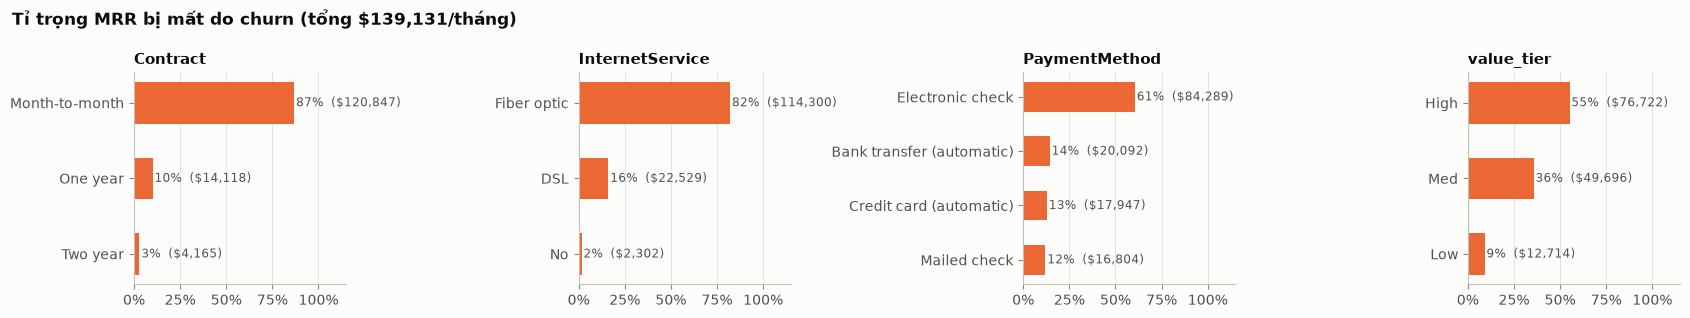

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, c in zip(axes, RAR_COLS):
    r = revenue_at_risk(c).iloc[::-1]
    ax.barh(r.index.astype(str), r["share_of_lost_mrr"], color=ORANGE, height=0.55)
    for i, (s_, v) in enumerate(zip(r["share_of_lost_mrr"], r["churned_mrr"])):
        ax.text(s_ + 0.01, i, f"{s_:.0%}  (${v:,.0f})", va="center", fontsize=8.5, color=INK_2)
    ax.set_xlim(0, 1.15)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(c, loc="left")
fig.suptitle(f"Tỉ trọng MRR bị mất do churn (tổng ${MRR_LOST:,.0f}/tháng)", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "f17_revenue_at_risk")
plt.show()

### 7.3 Phân khúc mô tả: Contract × InternetService × tenure
Ba biến này có liên hệ mạnh nhất với churn theo mục 5 và 6. Mỗi tổ hợp được xem như một **profile khách hàng**. Gán nhãn cho từng profile:
- **Risk tier** theo churn rate của nhóm: Low < 15%, Med 15–35%, High > 35%.
- **Value tier** theo `MonthlyCharges` trung bình của nhóm, dùng cùng ngưỡng tercile ở mục 7.1.

Bước này chỉ dùng groupby, **không cần preprocessing**. Bản phân khúc chính thức (decision tree, sau này là `p_churn` từ mô hình) sẽ làm sau bước preprocessing.

Bảng được lưu ở `eda_output/eda/segment_profile.csv`.

In [36]:
RISK_BINS, RISK_LABELS = [0, 0.15, 0.35, 1], ["Low", "Med", "High"]
MIN_SEG_N = 50

tenure_seg = pd.cut(eda_v["tenure"], [-1, 12, 24, 72], labels=["0–12", "13–24", "25–72"])
seg = (eda_v.assign(tenure_seg=tenure_seg)
       .groupby(["Contract", "InternetService", "tenure_seg"], observed=True)
       .agg(n=("churn_flag", "size"), churn_rate=("churn_flag", "mean"),
            avg_monthly=("MonthlyCharges", "mean"), avg_tenure=("tenure", "mean"),
            churned_mrr=("churned_mrr", "sum"))
       .reset_index())
seg["share_of_customers"] = seg["n"] / len(eda_v)
seg["share_of_lost_mrr"] = seg["churned_mrr"] / MRR_LOST
seg["lift"] = seg["churn_rate"] / BASE_RATE
seg["risk_tier"] = pd.cut(seg["churn_rate"], RISK_BINS, labels=RISK_LABELS, include_lowest=True)
seg["value_tier"] = pd.cut(seg["avg_monthly"], [0, VALUE_EDGES[1], VALUE_EDGES[2], np.inf], labels=["Low", "Med", "High"])
seg["profile"] = seg["risk_tier"].astype(str) + " risk / " + seg["value_tier"].astype(str) + " value"
seg["small_sample"] = seg["n"] < MIN_SEG_N
seg = seg.sort_values("churned_mrr", ascending=False).reset_index(drop=True)
seg.to_csv(TAB_DIR / "segment_profile.csv", index=False)

print(f"{len(seg)} tổ hợp; {seg['small_sample'].sum()} tổ hợp có n < {MIN_SEG_N} "
      f"({seg.loc[seg['small_sample'], 'n'].sum()} khách) – chỉ tham khảo, không kết luận")
seg_fmt = {"n": "{:,}", "churn_rate": "{:.1%}", "avg_monthly": "${:.1f}", "avg_tenure": "{:.1f}",
           "churned_mrr": "${:,.0f}", "share_of_customers": "{:.1%}", "share_of_lost_mrr": "{:.1%}", "lift": "{:.2f}×"}
seg.drop(columns=["small_sample"]).style.format(seg_fmt)

26 tổ hợp; 6 tổ hợp có n < 50 (116 khách) – chỉ tham khảo, không kết luận


,Contract,InternetService,tenure_seg,n,churn_rate,avg_monthly,avg_tenure,churned_mrr,share_of_customers,share_of_lost_mrr,lift,risk_tier,value_tier,profile
0,Month-to-month,Fiber optic,0–12,916,70.2%,$82.1,4.8,"$53,178",13.0%,38.2%,2.65×,High,Med,High risk / Med value
1,Month-to-month,Fiber optic,25–72,787,38.6%,$92.5,42.9,"$28,257",11.2%,20.3%,1.46×,High,High,High risk / High value
2,Month-to-month,Fiber optic,13–24,425,50.6%,$87.5,18.2,"$19,047",6.0%,13.7%,1.91×,High,High,High risk / High value
3,Month-to-month,DSL,0–12,690,42.5%,$47.9,4.4,"$13,352",9.8%,9.6%,1.60×,High,Low,High risk / Low value
4,One year,Fiber optic,25–72,509,19.3%,$99.1,54.2,"$9,965",7.2%,7.2%,0.73×,Med,High,Med risk / High value
5,Two year,Fiber optic,25–72,428,7.2%,$104.6,65.3,"$3,246",6.1%,2.3%,0.27×,Low,High,Low risk / High value
6,Month-to-month,DSL,13–24,232,23.7%,$52.7,18.0,"$2,765",3.3%,2.0%,0.89×,Med,Med,Med risk / Med value
7,One year,DSL,25–72,449,7.8%,$62.3,47.1,"$2,308",6.4%,1.7%,0.29×,Low,Med,Low risk / Med value
8,Month-to-month,DSL,25–72,301,15.3%,$53.7,39.9,"$2,250",4.3%,1.6%,0.58×,Med,Med,Med risk / Med value
9,Month-to-month,No,0–12,388,22.7%,$20.3,3.9,"$1,771",5.5%,1.3%,0.85×,Med,Low,Med risk / Low value


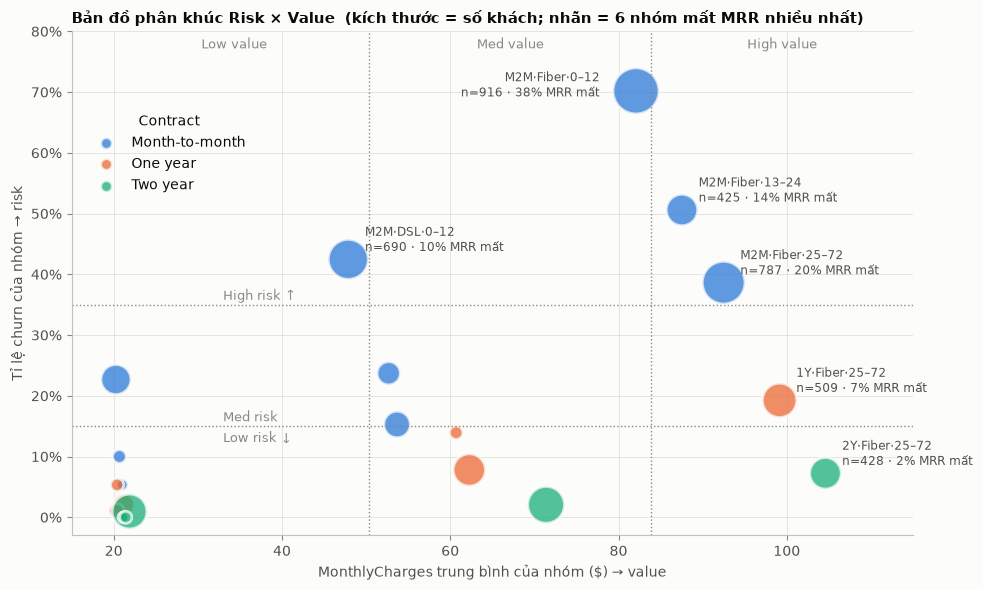

In [37]:
SHORT = {"Month-to-month": "M2M", "One year": "1Y", "Two year": "2Y", "Fiber optic": "Fiber", "DSL": "DSL", "No": "NoNet"}
plot_seg = seg[~seg["small_sample"]]

fig, ax = plt.subplots(figsize=(10, 6))
for contract, color in CONTRACT_COLORS.items():
    s = plot_seg[plot_seg["Contract"] == contract]
    ax.scatter(s["avg_monthly"], s["churn_rate"], s=s["n"] * 1.2, color=color, alpha=0.75,
               edgecolor=SURFACE, linewidth=2, label=contract)
for y in RISK_BINS[1:-1]:
    ax.axhline(y, color=MUTED, ls=":", lw=1)
for x in VALUE_EDGES[1:-1]:
    ax.axvline(x, color=MUTED, ls=":", lw=1)
for lab, y in [("High risk ↑", RISK_BINS[2]), ("Med risk", RISK_BINS[1])]:
    ax.text(33, y + 0.008, lab, color=MUTED, fontsize=9)
ax.text(33, RISK_BINS[1] - 0.008, "Low risk ↓", color=MUTED, fontsize=9, va="top")
for xv, lab in zip([(VALUE_EDGES[0] + VALUE_EDGES[1]) / 2, (VALUE_EDGES[1] + VALUE_EDGES[2]) / 2,
                    (VALUE_EDGES[2] + 115) / 2], ["Low value", "Med value", "High value"]):
    ax.text(xv, 0.79, lab, color=MUTED, fontsize=9, ha="center", va="top")
for _, r in plot_seg.nlargest(6, "churned_mrr").iterrows():
    left = r["churn_rate"] > 0.6   # nhóm cao nhất: đặt nhãn bên trái để không tràn khung
    ax.annotate(f"{SHORT[r['Contract']]}·{SHORT[r['InternetService']]}·{r['tenure_seg']}\n"
                f"n={r['n']:,} · {r['share_of_lost_mrr']:.0%} MRR mất",
                (r["avg_monthly"], r["churn_rate"]), xytext=(-26 if left else 12, -4 if left else 6),
                textcoords="offset points", ha="right" if left else "left", fontsize=8.5, color=INK_2)
ax.set_xlim(15, 115)
ax.set_ylim(-0.03, 0.80)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="MonthlyCharges trung bình của nhóm ($) → value", ylabel="Tỉ lệ churn của nhóm → risk")
ax.set_title("Bản đồ phân khúc Risk × Value  (kích thước = số khách; nhãn = 6 nhóm mất MRR nhiều nhất)", loc="left")
lgnd = ax.legend(title="Contract", loc="upper left", bbox_to_anchor=(0.01, 0.86))
for h in lgnd.legend_handles:
    h.set_sizes([70])
fig.tight_layout()
save_fig(fig, "f18_segment_bubble")
plt.show()

### 7.4 Ma trận Risk × Value ở cấp khách hàng
- **Trục risk:** mỗi khách nhận risk tier của profile mình thuộc về (mục 7.3).
- **Trục value:** value tier là của **từng khách**, theo tercile `MonthlyCharges` của chính khách đó.

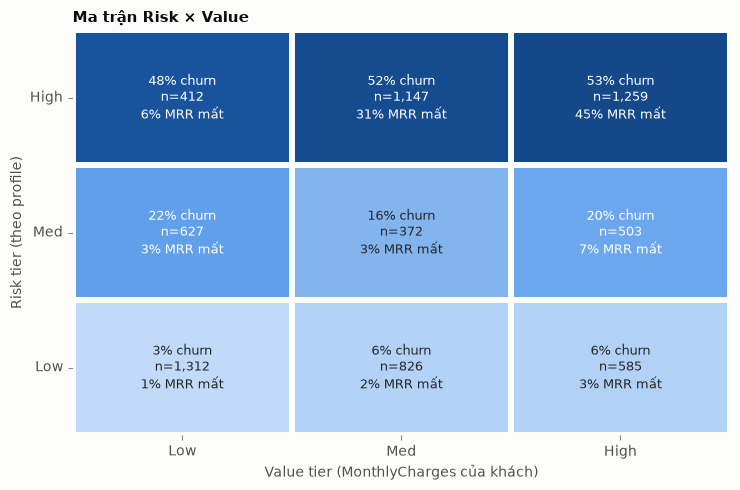

In [38]:
cust = eda_v.assign(tenure_seg=tenure_seg).merge(
    seg[["Contract", "InternetService", "tenure_seg", "risk_tier"]],
    on=["Contract", "InternetService", "tenure_seg"], how="left",
)
assert cust["risk_tier"].notna().all() and len(cust) == len(eda_v)

order_r, order_v = ["High", "Med", "Low"], ["Low", "Med", "High"]
m_n = pd.crosstab(cust["risk_tier"], cust["value_tier"]).reindex(index=order_r, columns=order_v)
m_rate = cust.pivot_table(index="risk_tier", columns="value_tier", values="churn_flag", aggfunc="mean", observed=False).reindex(index=order_r, columns=order_v)
m_lost = cust.pivot_table(index="risk_tier", columns="value_tier", values="churned_mrr", aggfunc="sum", observed=False).reindex(index=order_r, columns=order_v)

matrix = pd.concat({"n": m_n, "churn_rate": m_rate, "churned_mrr": m_lost, "share_of_lost_mrr": m_lost / MRR_LOST}, axis=1)
matrix.to_csv(TAB_DIR / "risk_value_matrix.csv")

annot = (m_rate.map(pct, digits=0) + " churn\nn=" + m_n.map("{:,}".format)
         + "\n" + (m_lost / MRR_LOST).map(pct, digits=0) + " MRR mất")
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(m_rate, annot=annot, fmt="", cmap=SEQ_CMAP, vmin=0, vmax=0.6, linewidths=3, linecolor=SURFACE,
            cbar=False, ax=ax, annot_kws={"fontsize": 9.5})
ax.set(xlabel="Value tier (MonthlyCharges của khách)", ylabel="Risk tier (theo profile)")
ax.set_title("Ma trận Risk × Value", loc="left")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
save_fig(fig, "f19_risk_value_matrix")
plt.show()

## 8. Tổng hợp

### 8.1 Insight chính

1. **Quy mô vấn đề.** 26.5% khách churn (1,869 / 7,043). Nhóm này chiếm **30.5% MRR**, tức khoảng $139K trên tổng $456K mỗi tháng. Khách churn trả cước cao hơn mức trung bình (median `MonthlyCharges` $79.7 so với $64.4 ở nhóm ở lại).
2. **Hợp đồng là driver mạnh nhất** (Cramér's V = 0.41). Tỉ lệ churn: Month-to-month 42.7%, One year 11.3%, Two year 2.8%. Riêng nhóm Month-to-month gây ra **87% MRR bị mất**.
3. **Giai đoạn đầu là nguy hiểm nhất.**
   - Churn ở nhóm tenure 0–6 tháng là 52.9%, giảm xuống 9.5% ở nhóm 49–72 tháng.
   - Median tenure của khách churn là 10 tháng, so với 38 tháng ở khách ở lại.
   - Tuy vậy, với hợp đồng Month-to-month, churn vẫn còn **26%** ngay cả sau hơn 4 năm. Tenure dài không tự loại bỏ rủi ro.
4. **Fiber optic và Electronic check.**
   - Fiber optic churn 41.9%, DSL 19.0%. Fiber optic chiếm **82% MRR bị mất**.
   - Electronic check churn 45.3% (lift 1.71×, cao nhất trong các nhóm), chiếm 61% MRR bị mất.
   - Tổ hợp Month-to-month × Fiber có churn 55% (n = 2,128). Month-to-month × Electronic check có churn 54% (n = 1,850).
5. **Dịch vụ "bảo vệ".** Khách không có `OnlineSecurity` / `TechSupport` churn khoảng 42%, khách có dịch vụ này chỉ khoảng 15%. `OnlineBackup` và `DeviceProtection` có xu hướng tương tự nhưng yếu hơn. Streaming có liên hệ yếu (V = 0.23).
6. **Rủi ro tập trung ở nhóm giá trị cao, nhưng không tăng đều theo cước.**
   - Theo 3 value tier, churn tăng dần: Low 15.9%, Med 29.7%, High 34.1%. Tier High chiếm **55% MRR bị mất**.
   - Theo decile (mục 7.1), quan hệ **không đơn điệu**: churn tăng từ 8.5% ($20) lên 41% ($98), rồi **giảm còn 25%** ở decile cước cao nhất ($107). Chia 3 tier đã che mất đoạn giảm này.
   - Hệ quả cho bài toán targeting: nhắm theo rủi ro hay nhắm theo giá trị phần lớn đều chỉ về cùng một nhóm khách.
7. **Phân khúc ưu tiên.**
   - Ba profile **Month-to-month × Fiber** (tenure 0–12, 13–24, 25–72) chỉ chiếm 30% số khách nhưng gây ra **72% MRR bị mất**.
   - Riêng nhóm M2M·Fiber·0–12 có 916 khách, churn 70%, cước trung bình $82 và chiếm 38% MRR bị mất. Nhóm này bị gán "Med value" chỉ vì cước trung bình $82.1 nằm sát ngưỡng tercile $83.9.
   - Trên ma trận Risk × Value, ô **High risk × Med/High value** gồm 2,406 khách (34%) và chiếm **76% MRR bị mất**. Đây là nhóm mục tiêu chính của chiến dịch giữ chân.
   - Ô Low risk × High value (585 khách, churn 6%) nên được chăm sóc bằng loyalty, không cần ưu đãi giảm giá.
8. **Nhân khẩu học.**
   - `gender` (p = 0.49) và `PhoneService` (p = 0.34) **không liên hệ** với churn.
   - `SeniorCitizen = Yes` có churn 41.7% (lift 1.57×). Cần lưu ý về fairness khi thiết kế chính sách ưu đãi theo tuổi.

### 8.2 Ghi chú cho preprocessing

| # | Vấn đề phát hiện | Bằng chứng | Hướng xử lý đề xuất |
|---|---|---|---|
| 1 | `TotalCharges` có kiểu `object`, chứa 11 chuỗi rỗng | Mục 2.1. Cả 11 dòng đều có `tenure = 0` (khách mới, chưa có hoá đơn), đều `Churn = No`, 10/11 là hợp đồng Two year | Ép sang số. Điền 0 (hợp lý về nghiệp vụ) hoặc loại bỏ (chỉ 0.16% dữ liệu). Ghi rõ lựa chọn |
| 2 | `SeniorCitizen` mã hoá 0/1, khác các cột nhị phân còn lại | Mục 2.2 | Thống nhất một kiểu mã hoá |
| 3 | Nhãn `"No internet service"` (1,526 dòng × 6 cột) và `"No phone service"` (682 dòng) dư thừa | Mục 2.4b: trùng khớp 100% với `InternetService = No` / `PhoneService = No` | Gộp về `"No"`, vì thông tin đã nằm trong cột gốc. Việc này giảm số cột dummy và giảm đa cộng tuyến |
| 4 | Đa cộng tuyến `TotalCharges` ≈ `tenure × MonthlyCharges` | r = 0.9996, VIF(TotalCharges) = 9.5 | Với logistic regression: bỏ `TotalCharges`, hoặc thay bằng biến chênh lệch cước (khoảng 5% khách lệch hơn 10%) |
| 5 | Phân phối lệch | Skew(TotalCharges) = 0.96. `tenure` có dạng hai đỉnh ở 2 đầu | Scale cho logistic regression (có thể log-transform `TotalCharges`). Mô hình cây không cần |
| 6 | Mất cân bằng lớp, tỉ lệ khoảng 2.8 : 1 | Mục 3 | Stratified split, `class_weight`, đánh giá bằng PR-AUC. Cần **calibration** sau khi dùng class weight |
| 7 | 22 dòng trùng toàn bộ đặc trưng (42 dòng liên quan) | Mục 2.3: `customerID` khác nhau, đều là Month-to-month | Giữ lại, vì đây là các khách khác nhau có profile đơn giản giống nhau. Không phải lỗi |
| 8 | `customerID` là cột định danh | Mục 1 | Loại khỏi feature, giữ làm khoá cho bảng targeting |
| 9 | Không có ngoại lai theo IQR, không có nhóm quá hiếm (nhóm nhỏ nhất có 682 khách) | Mục 2.5, 1.2 | Không cần xử lý ngoại lai hay gộp nhóm hiếm |
| 10 | Biến yếu: `gender`, `PhoneService` | Mục 5.3: không có ý nghĩa thống kê | Vẫn giữ cho mô hình, nhưng dự kiến importance thấp. `gender` và `SeniorCitizen` cần được xem xét trong phần fairness |
| 11 | Biến phân loại dạng chuỗi | Toàn bộ | One-hot encoding. `Contract` có thể mã hoá dạng ordinal |
| 12 | Churn không tăng đều theo `MonthlyCharges` | Mục 7.1 (f16): tăng đến decile 9 rồi giảm ở decile 10 | Cho logistic regression: chia khoảng hoặc dùng dạng phi tuyến. Mô hình cây không cần |

Quyết định cuối cùng cho từng điểm trên, kèm kiểm tra tuyến tính với log-odds, được ghi trong [`docs/eda_to_preprocessing.md`](../docs/eda_to_preprocessing.md) và [`notebooks/02_preprocessing.ipynb`](02_preprocessing.ipynb).

### 8.3 Giới hạn của phân tích

- **Tương quan, không phải nhân quả.** Ví dụ, hợp đồng Two year có churn 2.8%, nhưng **không** thể kết luận "chuyển khách sang hợp đồng 2 năm sẽ giảm churn". Khách tự chọn loại hợp đồng (selection bias). Dữ liệu không có chiến dịch ngẫu nhiên nào, nên không ước lượng được uplift.
- **Dữ liệu dạng snapshot.** Quan hệ giữa tenure và churn là cắt ngang và có thể chứa survivorship bias: khách tenure dài là những người "đã sống sót".
- **Dữ liệu mẫu, hư cấu** (IBM sample). Không rõ thị trường, thời điểm hay cấu trúc giá, nên kết quả có thể không áp dụng được cho một nhà mạng thực tế (external validity).
- **Proxy giá trị còn thô.** `MonthlyCharges` là doanh thu, chưa phải lợi nhuận, và chưa tính thời gian còn lại. Proxy chính thức sẽ được xây ở bước Value.
- **Ngưỡng phân khúc do người phân tích chọn** (15% / 35%, tercile). Các nhóm có n < 50 không đủ tin cậy. Ngoài ra, vì n lớn nên hầu hết p-value đều rất nhỏ; nên dựa vào **effect size** (Cramér's V, lift) để đánh giá.

In [39]:
print("Hình đã lưu:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.relative_to(ROOT))
print("Bảng đã lưu:")
for p in sorted(TAB_DIR.glob("*.csv")):
    print("  ", p.relative_to(ROOT))

Hình đã lưu:
   outputs\figures\f01_churn_distribution.png
   outputs\figures\f02_categorical_distribution.png
   outputs\figures\f03_numeric_distribution.png
   outputs\figures\f04_churn_contract_billing.png
   outputs\figures\f05_churn_internet_phone.png
   outputs\figures\f06_churn_addons.png
   outputs\figures\f07_churn_demographics.png
   outputs\figures\f08_numeric_by_churn.png
   outputs\figures\f09_association_strength.png
   outputs\figures\f10_driver_lift.png
   outputs\figures\f11_correlation.png
   outputs\figures\f12_heatmap_interactions.png
   outputs\figures\f13_churn_by_tenure_contract.png
   outputs\figures\f14_scatter_tenure_charges.png
   outputs\figures\f15_heatmap_tenure_charges.png
   outputs\figures\f16_churn_by_value.png
   outputs\figures\f17_revenue_at_risk.png
   outputs\figures\f18_segment_bubble.png
   outputs\figures\f19_risk_value_matrix.png
   outputs\figures\p01_engineered_flags.png
   outputs\figures\p02_linearity_logit.png
   outputs\figures\q01_total